In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
import seaborn as sns


df = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 1, 2, 8],
    "iq"         : [30, 50, 52, 65, 68, 70, 72, 80],
    "result"     : [0, 0, 1, 0, 1, 1, 1, 1]
})
df

X = df[["study_hours", "iq"]]
y = df["result"]

model = LogisticRegression()
model.fit(X, y)

new_student = pd.DataFrame({"study_hours": [2], "iq" :[40]})

probabilities = model.predict_proba(new_student)
prediction = model.predict(new_student)

print("Class probabilities:", probabilities.round(3))
print("Predicted class:", prediction[0])
print("Weight:", model.coef_[0][0])
print("Bias:", model.intercept_[0])


Class probabilities: [[0.895 0.105]]
Predicted class: 0
Weight: -0.06937446102426911
Bias: -7.435769930125365


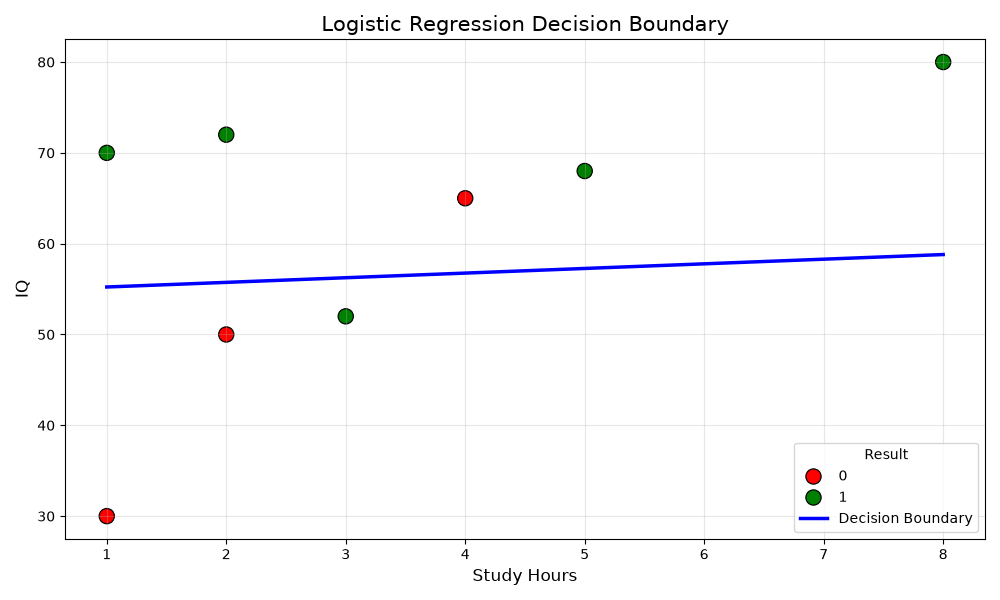

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

df = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 1, 2, 8],
    "iq":          [30, 50, 52, 65, 68, 70, 72, 80],
    "result":      [0, 0, 1, 0, 1, 1, 1, 1]
})

X = df[["study_hours", "iq"]]
y = df["result"]

model = LogisticRegression()
model.fit(X, y)

# Extract model parameters
w1, w2 = model.coef_[0]
bias = model.intercept_[0]

# Calculate decision boundary: iq = -(w1 * study_hours + bias) / w2
hours = np.linspace(df["study_hours"].min(),
                    df["study_hours"].max(), 200)

iq_boundary = -(w1 * hours + bias) / w2

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="study_hours",
    y="iq",
    hue="result",
    palette={0: "red", 1: "green"},
    s=120,
    edgecolor="black",
    ax=ax
)

ax.plot(
    hours,
    iq_boundary,
    color="blue",
    linewidth=2.5,
    label="Decision Boundary"
)

ax.set_title("Logistic Regression Decision Boundary", fontsize=15)
ax.set_xlabel("Study Hours", fontsize=12)
ax.set_ylabel("IQ", fontsize=12)
ax.grid(alpha=0.3)
ax.legend(title="Result", frameon=True)

plt.tight_layout()
plt.show()